# wstępne przejrzenie plików Twitter

In [28]:
import os
import pandas as pd
from pathlib import Path
import glob
import numpy as np

In [7]:
def find_data_file(filename):
    current = Path.cwd()
    for parent in [current] + list(current.parents):
        target = parent / "ukraine-source" / filename
        if target.exists():
            return target
        target_direct = parent / filename
        if target_direct.exists():
            return target_direct
    return None

csv_path = find_data_file("with_sentiment.csv")

if csv_path is None:
    print("Nie znaleziono pliku 'with_sentiment.csv'. Sprawdź, czy znajduje się w folderze 'ukraine-source/'.")
    print(f"Bieżący katalog roboczy notatnika: {os.getcwd()}")
else:
    print(f"Wczytywanie pliku z: {csv_path}")
    df = pd.read_csv(csv_path, low_memory=False)
    print(f"Sukces! Wczytano {len(df):,} wierszy.")

Wczytywanie pliku z: C:\Users\Mateusz\Desktop\Python\Magisterka\AMC\AMC_lab\ukraine-source\with_sentiment.csv
Sukces! Wczytano 55,035 wierszy.


In [8]:
print("=" * 60)
print(f"Liczba wszystkich wierszy: {len(df):,}")
print(f"Liczba unikalnych treści (Tweet): {df['Tweet'].nunique():,}")
print("=" * 60)

df["Tweet Date (UTC)"] = pd.to_datetime(df["Tweet Date (UTC)"])
min_date = df["Tweet Date (UTC)"].min()
max_date = df["Tweet Date (UTC)"].max()
print(f"Zakres dat wpisów: od {min_date} do {max_date}")

print("\n[Stary Słownik] Rozkład automatycznych etykiet Sentiment_Label:")
print(df["Sentiment_Label"].value_counts(dropna=False))

key_cols = [
    "Tweet Date (UTC)",
    "Tweet",
    "Sentiment_Label",
    "Sentiment_Score",
    "Retweet Count",
    "Favorite Count",
]
print("\nPodgląd 3 pierwszych wierszy (kluczowe kolumny):")
display(df[key_cols].head(3))

missing_tweets = df["Tweet"].isna().sum()
print(f"\nLiczba wierszy z pustą treścią 'Tweet': {missing_tweets}")

Liczba wszystkich wierszy: 55,035
Liczba unikalnych treści (Tweet): 22,634
Zakres dat wpisów: od 2022-02-24 09:23:58 do 2022-12-31 23:47:06

[Stary Słownik] Rozkład automatycznych etykiet Sentiment_Label:
Sentiment_Label
neutral     28421
negative    22829
positive     3785
Name: count, dtype: int64

Podgląd 3 pierwszych wierszy (kluczowe kolumny):


,Tweet Date (UTC),Tweet,Sentiment_Label,Sentiment_Score,Retweet Count,Favorite Count
0,2022-02-24 09:23:58,Jadę w autobusie nr 523 młody chłopak rozmawia...,negative,0.997843,484,7146
1,2022-02-25 07:00:30,Ukraińcy od ręki dostają w Polsce mieszkania s...,neutral,0.999616,105,475
2,2022-02-25 09:34:13,Na najbliższym posiedzeniu Zarządu PZPN zgłosz...,positive,0.992566,268,9468



Liczba wierszy z pustą treścią 'Tweet': 0


tworzenie pliku csv unikalne tweety oraz nowe kolumny dla etykiet z llma

In [10]:
print(f"Wczytywanie z: {csv_path}")

df_full = pd.read_csv(csv_path, low_memory=False)
print(f"Pełny zbiór: {len(df_full):,} wierszy")

df_unique = df_full.drop_duplicates(subset=["Tweet"]).copy()
print(f"Unikalne treści: {len(df_unique):,} wierszy (redukcja o {len(df_full) - len(df_unique):,} powtórzeń/retweetów)")

df_unique["unique_id"] = range(1, len(df_unique) + 1)
df_unique["llm_label"] = ""
df_unique["llm_reasoning"] = ""

cols = [
    "unique_id",
    "Tweet",
    "Sentiment_Label",
    "Sentiment_Score",
    "Retweet Count",
    "Favorite Count",
    "Tweet Date (UTC)",
    "llm_label",
    "llm_reasoning",
]
df_unique_export = df_unique[cols]

output_dir = csv_path.parent
output_path = output_dir / "twitter_unique_llm.csv"

df_unique_export.to_csv(output_path, index=False, encoding="utf-8-sig")
print(f"Pomyślnie zapisano plik w: {output_path}")

Wczytywanie z: C:\Users\Mateusz\Desktop\Python\Magisterka\AMC\AMC_lab\ukraine-source\with_sentiment.csv
Pełny zbiór: 55,035 wierszy
Unikalne treści: 22,634 wierszy (redukcja o 32,401 powtórzeń/retweetów)
Pomyślnie zapisano plik w: C:\Users\Mateusz\Desktop\Python\Magisterka\AMC\AMC_lab\ukraine-source\twitter_unique_llm.csv


# Połączenie się z Gemini

In [11]:
from dotenv import load_dotenv
from google import genai

In [12]:
load_dotenv()

api_key = os.getenv("GEMINI_API_KEY")

if not api_key:
    raise ValueError(
        "Nie znaleziono klucza GEMINI_API_KEY! Sprawdź, czy plik .env istnieje i czy zawiera właściwą nazwę zmiennej."
    )

print("Klucz API wczytany pomyślnie. Inicjalizacja klienta...")

client = genai.Client(api_key=api_key)

try:
    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents="Odpowiedz jednym krótkim zdaniem potwierdzającym, że połączenie z API działa prawidłowo.",
    )

    print("\n Status połączenia: OK")
    print("Odpowiedź z modelu Gemini:")
    print("-" * 50)
    print(response.text)
    print("-" * 50)

except Exception as e:
    print(f"\n Błąd podczas połączenia z API: {e}")

Klucz API wczytany pomyślnie. Inicjalizacja klienta...

 Status połączenia: OK
Odpowiedź z modelu Gemini:
--------------------------------------------------
Połączenie z API działa prawidłowo.
--------------------------------------------------


# porównanie labeli z gemini do moich

In [23]:
import json
import time
import pandas as pd
from pathlib import Path
from dotenv import load_dotenv
from google import genai
from google.genai import types
from sklearn.metrics import classification_report, cohen_kappa_score

load_dotenv()
client = genai.Client()

df_a = pd.read_excel("../ukraine-source/anotacja_A.xlsx", sheet_name="Anotacja")
df_a1 = pd.read_excel("../ukraine-source/anotacja_A-1.xlsx", sheet_name="Anotacja")
df_gold = pd.concat([df_a, df_a1], ignore_index=True)

df_gold = df_gold.dropna(subset=["etykieta", "tekst_pl"]).copy()
print(f"Przygotowano {len(df_gold)} wpisów z Gold Standardu do walidacji.")

with open("../prompts/gemini_codebook.txt", "r", encoding="utf-8") as f:
    system_prompt = f.read()

BATCH_SIZE = 20
results = {}

print(" Uruchamianie klasyfikacji Gemini dla Gold Standardu...")

for i in range(0, len(df_gold), BATCH_SIZE):
    batch = df_gold.iloc[i:i+BATCH_SIZE]

    payload = []
    for idx, row in batch.iterrows():
        payload.append({"id": int(idx), "text": str(row["tekst_pl"])[:400]})

    user_message = f"Przeanalizuj poniższą paczkę wpisów:\n{json.dumps(payload, ensure_ascii=False)}"

    try:
        response = client.models.generate_content(
            model="gemini-2.5-flash",
            contents=user_message,
            config=types.GenerateContentConfig(
                system_instruction=system_prompt,
                temperature=0.0,
                response_mime_type="application/json"
            )
        )
        parsed = json.loads(response.text)
        for item in parsed:
            results[item["id"]] = item["label"]

        print(f" Przetworzono wpisy {i+1} do {min(i+BATCH_SIZE, len(df_gold))}")
        time.sleep(4) # Ochrona limitu RPM
    except Exception as e:
        print(f" Błąd w paczce {i}: {e}")
        time.sleep(10)

df_gold["llm_label"] = df_gold.index.map(results)
df_eval = df_gold.dropna(subset=["llm_label"]).copy()

y_true = df_eval["etykieta"].tolist()
y_pred = df_eval["llm_label"].tolist()

print("\n" + "="*60)
print("RAPORT ZGODNOŚCI GEMINI VS HUMAN GOLD STANDARD")
print("="*60)
print(classification_report(y_true, y_pred, zero_division=0))

kappa = cohen_kappa_score(y_true, y_pred)
print(f"Wskaźnik Kohena (Cohen's Kappa): {kappa:.4f}")

Przygotowano 200 wpisów z Gold Standardu do walidacji.
 Uruchamianie klasyfikacji Gemini dla Gold Standardu...
 Przetworzono wpisy 1 do 20
 Przetworzono wpisy 21 do 40
 Przetworzono wpisy 41 do 60
 Przetworzono wpisy 61 do 80
 Przetworzono wpisy 81 do 100
 Przetworzono wpisy 101 do 120
 Przetworzono wpisy 121 do 140
 Przetworzono wpisy 141 do 160
 Przetworzono wpisy 161 do 180
 Przetworzono wpisy 181 do 200

RAPORT ZGODNOŚCI GEMINI VS HUMAN GOLD STANDARD
              precision    recall  f1-score   support

        anty       0.64      0.88      0.74        41
   neutralne       0.80      0.50      0.62        56
 nie_dotyczy       0.75      0.73      0.74        75
    niejasne       0.43      0.19      0.26        16
         pro       0.38      0.92      0.54        12

    accuracy                           0.67       200
   macro avg       0.60      0.64      0.58       200
weighted avg       0.70      0.67      0.66       200

Wskaźnik Kohena (Cohen's Kappa): 0.5505


In [27]:
import pandas as pd

df = pd.read_csv("../ukraine-source/twitter_unique_llm.csv", sep=None, engine="python")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

display(df)

,﻿unique_id,Tweet,Sentiment_Label,Sentiment_Score,Retweet Count,Favorite Count,Tweet Date (UTC),llm_label,llm_reasoning
0,1,Jadę w autobusie nr 523 młody chłopak rozmawia przez telefon po ukraińsku i płacze. Obok pani po polsku trajkocze i nadzieniu pączków. Przepaść.,negative,0.997843,484,7146,2022-02-24 09:23:58,neutralne,NaN
1,2,"Ukraińcy od ręki dostają w Polsce mieszkania socjalne, na które Polacy czekają latami.\r\nUkraińcy są zwolnieni z kwarantanny po przekroczeniu polskiej granicy.\r\nUkraińcy mają nieograniczony dostęp do opieki medycznej w Polsce.\r\n\r\nLudzie, nie jestem antyukraińska, ale coś tu nie gra.",neutral,0.999616,105,475,2022-02-25 07:00:30,anty,NaN
2,3,"Na najbliższym posiedzeniu Zarządu PZPN zgłoszę wniosek, aby Ukraińcy nie byli wliczani do limitu cudzoziemców spoza krajów UE. Dla wszystkich szczebli rozgrywek piłkarskich. Dzięki temu zwiększymy ich szanse na znalezienie klubów w Polsce w tym trudnym czasie 🇵🇱🤝🇺🇦",positive,0.992566,268,9468,2022-02-25 09:34:13,pro,NaN
3,4,Proszę o podawanie dalej. Jeżeli ktoś z was pracuje lub zna osoby z Ukrainy którzy potrzebują pomocy z transportem rodzin z granicy zupełnie za darmo przewiozę w dowolne miejsce w PL. 663 994 220 lub saklak@icloud.com,neutral,0.999720,1749,2430,2022-02-25 14:53:57,pro,NaN
4,5,"#Teleexpress | Mieszkają w Polsce od wielu lat, mają tu pracę i mogliby być nadal bezpieczni - wyjeżdżają jednak by bronić swojej ojczyzny. Ukraińcy chcą walczyć z rosyjskim najeźdźcą. https://t.co/NOp3W8H7KP",neutral,0.999760,1,4,2022-02-25 16:40:00,nie_dotyczy,NaN
5,6,"#Przemyśl Oferujemy przejazd do Krakowa/Katowic. Ukraińcy nie chcą. Oni chcą do Włoch i Norwegii. Mówią, że w Polsce tez będzie wojna… https://t.co/x8TQ506krl",neutral,0.999448,14,42,2022-02-26 02:10:15,anty,NaN
6,7,"Ukraińcy wdzięczni Polsce za pomoc. Mieszkanka Lwowa podeszła do reportera Polsat News, w czasie jego relacji, by mu podziękować. - Dziękujemy, dziękujemy wam bardzo, jak nie macie gdzie spać, to zapraszam do mnie - mówiła. https://t.co/8SRCIz0xUd",positive,0.999685,970,6514,2022-02-27 10:13:23,pro,NaN
7,8,"Anglia🏴󠁧󠁢󠁥󠁮󠁧󠁿, Albania🇦🇱, Czechy🇨🇿, Dania🇩🇰, Irlandia🇮🇪, Norwegia🇳🇴, Szkocja🏴󠁧󠁢󠁳󠁣󠁴󠁿, Szwajcaria🇨🇭, Szwecja🇸🇪, Walia🏴󠁧󠁢󠁷󠁬󠁳󠁿… - piłkarska Europa idzie polską drogą. Razem jesteśmy silniejsi! #SolidarniZUkrainą\r\n\r\nDziękujemy! | Thank you!",positive,0.999773,1399,18729,2022-02-28 13:11:14,nie_dotyczy,NaN
8,9,Wychodzi na to że nie ma w Polsce miejsca dla Polaków?❗ Teraz będzie się Polaków wyrzucać na bruk bo ważniejsi ukraińcy? ❗ Jprdl 😠👇 https://t.co/pBXqcA7jUq,negative,0.999914,49,90,2022-02-28 20:33:59,anty,NaN
9,10,"Ten powszechny w Polsce huraoptymizm nie ma nic wspólnego z rzeczywistością. Mam wrażenie, że dominujący przekaz jest taki jakby Ukraińcy nie tylko wygrywali, ale zaraz mieli odbić Krym. Tymczasem mimo swojej ofiarności są oni sukcesywnie spychani, a Rosjanie zdobywają teren.",negative,0.999751,217,1952,2022-03-01 10:14:15,nie_dotyczy,NaN


# Wstęp dla Telegrama

In [30]:
file_paths = glob.glob("../data/telegram/posts_2022_part_*.csv")
print(f"Znaleziono plików: {len(file_paths)}")

dfs = [pd.read_csv(f, low_memory=False) for f in file_paths]
df_telegram = pd.concat(dfs, ignore_index=True)

print(f" Włączona baza Telegrama zawiera: {len(df_telegram):,} wierszy.")
df_telegram.head(3)

Znaleziono plików: 8
 Włączona baza Telegrama zawiera: 172,220 wierszy.


,id,peer_id,date,message,views,forwards
0,19629,1199979298,2022-11-16T05:01:30Z,"Друзья, всем привет!\n\nСтрасти накаляются. Казалось, хуже быть уже не может. Но, как известно из старой притчи, для того, чтобы всем «стало совсем весело», в дом срочно нужно привести козу. \nВ роли козы в данном случае выступили неопознанного вида ракеты в Польше. \n\nВ связи со вчерашним инцидентом, в Польше созвали экстренное совещание Комитета национальной безопасности. По его итогам будет решаться вопрос активизации статьи 4 устава НАТО. \n\nО чем идет речь? Официальная формулировка звучит так: «Договаривающиеся стороны всегда будут консультироваться друг с другом в случае, если, по мнению какой-либо из них, территориальная целостность, политическая независимость или безопасность какой-либо из Договаривающихся сторон окажутся под угрозой.» Переводя на русский, задействование 4-й статьи договора может привести к принятию совместного решения или действия от имени Альянса. \nКаким именно будет ответ? Сейчас предсказать тяжело. Вероятнее всего, последуют очередные более жесткие санкции. \n\nГоворя о возможных сценариях, председатель комитета Сената по международным отношениям, сенатор-демократ от штата Нью-Джерси Боб Менендес заявил, что преднамеренное нанесение удара по территории Польши может привести к применению статьи 5 устава НАТО. Нападение на одного из членов НАТО будет рассматриваться как нападение на всех членов альянса. Впервые за свою историю НАТО применила статью 5 после террористических актов, совершенных 11 сентября 2001 года против США.\n\nЧто будет в реальности? Мое мнение – НИЧЕГО. Будет совместное коммюнике. Будут требования к России немедленно… что-то сделать (покаяться, остановить боевые действия, объяснить причину и вообще…). \nВпрочем, уже сами американцы не убеждены, что это Россия… Боже, неужели опять Гондурас? \n\nКакие практические последствия мы можем увидеть? Скорее всего, дополнительные партии оружия Украине. Возможно, более дальнего действия. И, скорее всего, пока все. \nИбо козу, которая так некстати попала в переполненный дом, надо тихо удалить и обрадоваться, что без нее теперь можно жить и не тужить. \n\nКогда я вчера утром писал, «Впрочем, ноябрь-декабрь могут нам преподнести что-то более негативное, чем плохую экономическую статистику. Чувство пятой точки, которое редко подводит, подсказывает, что до конца года можно ожидать гадостей. Не могу дать четкое объяснения, но предполагаю, что рынок еще полетает. И далеко не факт, что по экономическим причинам», то имел в виду что-то гораздо худшее, чем эти две ракеты. Нет, что-то другое… \n\nПолагаю, «сюрпризы» еще впереди. \nКозы, как и лебеди, любят летать стайками.\n\n#геополитика\n\n@bitkogan",63821,177
1,17695,1199979298,2022-05-31T12:03:13Z,"Основное о новых санкциях\n\nПохоже на то, что несколько урезанному в своих масштабах, нефтяному эмбарго от старушки Европы все же быть. \n\nНефтяное «недоэмбарго». Глава Евросовета Шарль Мишель заявил, что лидеры стран Евросоюза договорились о запрете на импорт двух третей нефти из России. Отмечается, что страны ЕС планируют сократить импорт нефти из России до 90% к концу 2022 г.\n\nУпиравшейся Венгрии пообещали не перекрывать нефть через нефтепровод Дружба. Кстати, опасения Виктора Орбана были связаны не только с запретом покупать нефть, но и с голосами с Украины, предполагавшими, что с самим нефтепроводом может что-то случиться. Для того, чтобы уговорить его подписаться под всем пакетом санкций, ЕС обещал Венгрии компенсировать выпадающие объемы в случае форс-мажора с нефтепроводом. \n\nЦены на нефть моментально отреагировали. Нефтяные фьючерсы полетели вверх дальше. Brent в настоящий момент торгуется на уровне $123,8. Вчера заявления Федуна. Сегодня – решение Евросоюза. Интересно… какую причину завтра найдут для обоснования дальнейшего роста цен на черное золото.\n\nПожалуй, как и говорил вчера, начну потихоньку фиксировать «не обособленышей» в сфере нефтянки. На таком хайпе, пожалуй, можно немного и продать подросшие 

In [31]:
print("--- Podsumowanie struktury danych ---")
df_telegram.info()

print("\n--- Statystyki wyświetleń i udostępnień ---")
df_telegram[['views', 'forwards']] = df_telegram[['views', 'forwards']].apply(pd.to_numeric, errors='coerce')
print(df_telegram[['views', 'forwards']].describe())

--- Podsumowanie struktury danych ---
<class 'pandas.DataFrame'>
RangeIndex: 172220 entries, 0 to 172219
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   id        172220 non-null  int64
 1   peer_id   172220 non-null  int64
 2   date      172220 non-null  str  
 3   message   172220 non-null  str  
 4   views     172220 non-null  int64
 5   forwards  172220 non-null  int64
dtypes: int64(4), str(2)
memory usage: 7.9 MB

--- Statystyki wyświetleń i udostępnień ---
              views       forwards
count  1.722200e+05  172220.000000
mean   2.359375e+04      69.294960
std    6.310930e+04     345.220279
min    1.000000e+00       0.000000
25%    1.576000e+03       2.000000
50%    6.471000e+03      10.000000
75%    2.231825e+04      40.000000
max    9.869392e+06   51667.000000


In [32]:
# Usuwanie pustych wiadomości oraz dokładnych duplikatów tekstu
df_clean = df_telegram.dropna(subset=['message']).copy()
df_clean['message_clean'] = df_clean['message'].astype(str).str.strip()

initial_count = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['message_clean'])
removed = initial_count - len(df_clean)

print(f" Usunięto duplikatów treści: {removed:,}")
print(f" Unikalne posty do dalszej analizy/etykietowania: {len(df_clean):,}")

 Usunięto duplikatów treści: 60,128
 Unikalne posty do dalszej analizy/etykietowania: 112,092


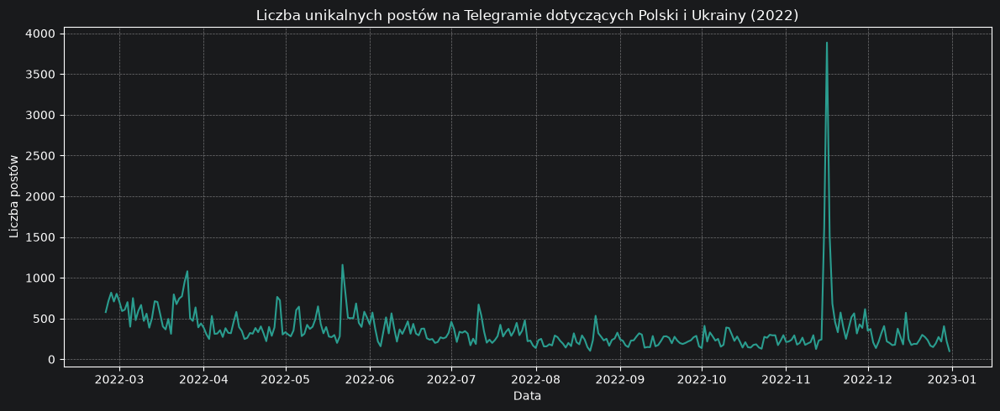

In [33]:
import matplotlib.pyplot as plt

df_clean['date'] = pd.to_datetime(df_clean['date'], errors='coerce')
df_clean['day'] = df_clean['date'].dt.date

daily_counts = df_clean.groupby('day').size()

plt.figure(figsize=(12, 5))
daily_counts.plot(kind='line', color='#2A9D8F', linewidth=1.5)
plt.title('Liczba unikalnych postów na Telegramie dotyczących Polski i Ukrainy (2022)')
plt.xlabel('Data')
plt.ylabel('Liczba postów')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [37]:
# 1. Ustalenie wielkości próby (10 000 wpisów = błąd pomiaru < 1% przy przedziale ufności 95%)
SAMPLE_SIZE = 10000

# 2. Przygotowanie podziału na miesiące do próbkowania warstwowego
df_clean['date'] = pd.to_datetime(df_clean['date'], errors='coerce')
df_clean['year_month'] = df_clean['date'].dt.to_period('M')

# 3. Losowanie z zachowaniem proporcji czasowych (random_state=42 zapewnia powtarzalność)
df_sample = (
    df_clean.groupby('year_month', group_keys=False)
    .sample(frac=SAMPLE_SIZE / len(df_clean), random_state=42)
    .reset_index(drop=True)
)

# Usunięcie pomocniczej kolumny
df_sample = df_sample.drop(columns=['year_month'])

print(f"Pobrano reprezentatywną próbkę: {len(df_sample):,} z {len(df_clean):,} unikalnych postów.")

Pobrano reprezentatywną próbkę: 10,001 z 112,092 unikalnych postów.


C:\Users\Mateusz\AppData\Local\Temp\ipykernel_5140\2981217363.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_clean['year_month'] = df_clean['date'].dt.to_period('M')


In [38]:
output_path = "../ukraine-source/telegram_unique_llm.csv"
df_sample.to_csv(output_path, index=False, encoding='utf-8-sig')
print(f" Zapisano gotowy plik do etykietowania: {output_path}")

 Zapisano gotowy plik do etykietowania: ../ukraine-source/telegram_unique_llm.csv


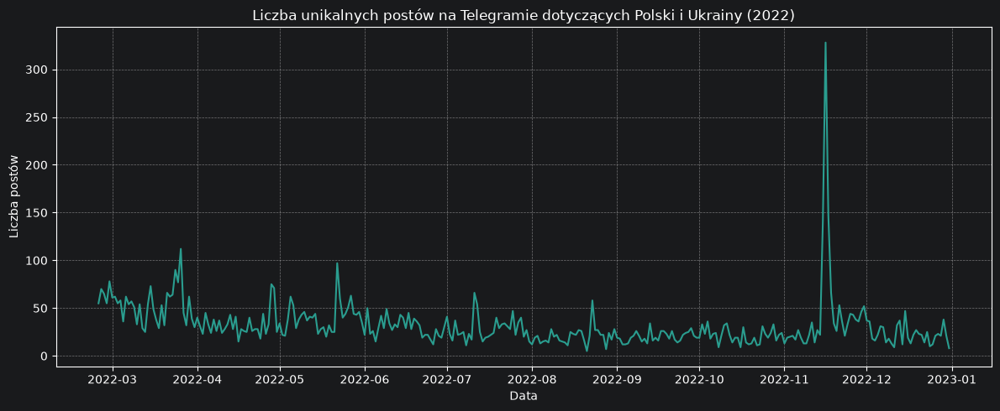

In [39]:
df_sample['date'] = pd.to_datetime(df_sample['date'], errors='coerce')
df_sample['day'] = df_sample['date'].dt.date

daily_counts = df_sample.groupby('day').size()

plt.figure(figsize=(12, 5))
daily_counts.plot(kind='line', color='#2A9D8F', linewidth=1.5)
plt.title('Liczba unikalnych postów na Telegramie dotyczących Polski i Ukrainy (2022)')
plt.xlabel('Data')
plt.ylabel('Liczba postów')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [40]:
print("--- Podsumowanie struktury danych ---")
df_sample.info()

--- Podsumowanie struktury danych ---
<class 'pandas.DataFrame'>
RangeIndex: 10001 entries, 0 to 10000
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   id             10001 non-null  int64              
 1   peer_id        10001 non-null  int64              
 2   date           10001 non-null  datetime64[us, UTC]
 3   message        10001 non-null  str                
 4   views          10001 non-null  int64              
 5   forwards       10001 non-null  int64              
 6   message_clean  10001 non-null  str                
 7   day            10001 non-null  object             
dtypes: datetime64[us, UTC](1), int64(4), object(1), str(2)
memory usage: 625.2+ KB


In [43]:
import json
import pandas as pd
import requests

# Load Codebook and sample data
CODEBOOK_FILE = "../prompts/gemini_codebook.txt"
INPUT_FILE = "../ukraine-source/telegram_unique_llm.csv"

with open(CODEBOOK_FILE, "r", encoding="utf-8") as f:
    codebook = f.read()

df = pd.read_csv(INPUT_FILE, low_memory=False)
sample_posts = df.head(5)  # Pobieramy pierwsze 5 postów (cyrylica)

formatted_posts = "\n".join(
    [f"ID {row['id']}: {str(row['message'])[:500]}" for _, row in sample_posts.iterrows()]
)

prompt = f"""{codebook}

Przeanalizuj poniższe posty z Telegrama (napisane po rosyjsku/ukraińsku) i przypisz do każdego z nich kategorie z Codebooka.
Odpowiedz WYŁĄCZNIE poprawnym obiektem JSON w formacie listy:
[
  {{"id": "ID_POSTU", "category": "NAZWA_KATEGORII", "sentiment": "NEUTRAL/POSITIVE/NEGATIVE"}}
]

POSTY DO PRZEANALIZOWANIA:
{formatted_posts}
"""

payload = {
    "model": "qwen2.5:3b",
    "prompt": prompt,
    "stream": False,
    "options": {"temperature": 0.1, "num_ctx": 4096},
}

print("Wysyłanie próby do Ollamy...")
response = requests.post("http://localhost:11434/api/generate", json=payload, timeout=60)

if response.status_code == 200:
    raw_response = response.json().get("response", "")
    print("\n Surowa odpowiedź modelu:")
    print(raw_response)
else:
    print(f" Błąd połączenia z Ollamą: {response.status_code}")

Wysyłanie próby do Ollamy...

 Surowa odpowiedź modelu:
[
  {"id": "27143", "category": "neutralne", "sentiment": "NEUTRAL"},
  {"id": "4282", "category": "nie_dotyczy", "sentiment": "NEUTRAL"},
  {"id": "1745", "category": "anty", "sentiment": "NEGATIVE"},
  {"id": "7151", "category": "pro", "sentiment": "POSITIVE"},
  {"id": "82", "category": "pro", "sentiment": "POSITIVE"}
]


In [44]:
file_path = "../ukraine-source/telegram_unique_llm.csv"
df = pd.read_csv(file_path, low_memory=False)

# Dodanie kolumny llm_label, jeśli jej jeszcze nie ma
if "llm_label" not in df.columns:
    df["llm_label"] = ""

# Zapis pliku z kompletem kolumn
df.to_csv(file_path, index=False, encoding="utf-8-sig")

print(f" Zaktualizowano plik: {file_path}")
print(f" Liczba wierszy: {len(df):,}")
print(f" Lista kolumn: {df.columns.tolist()}")

 Zaktualizowano plik: ../ukraine-source/telegram_unique_llm.csv
 Liczba wierszy: 10,001
 Lista kolumn: ['id', 'peer_id', 'date', 'message', 'views', 'forwards', 'message_clean', 'day', 'llm_label']


In [ ]:
df = pd.read_csv("../ukraine-source/telegram_unique_llm.csv", sep=None, engine="python")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

display(df)